<a href="https://colab.research.google.com/github/zaaz-png/results/blob/main/fds7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import files
uploaded= files.upload()

data= pd.read_csv('cleaned_dataset2.csv')

Saving cleaned_dataset2.csv to cleaned_dataset2.csv


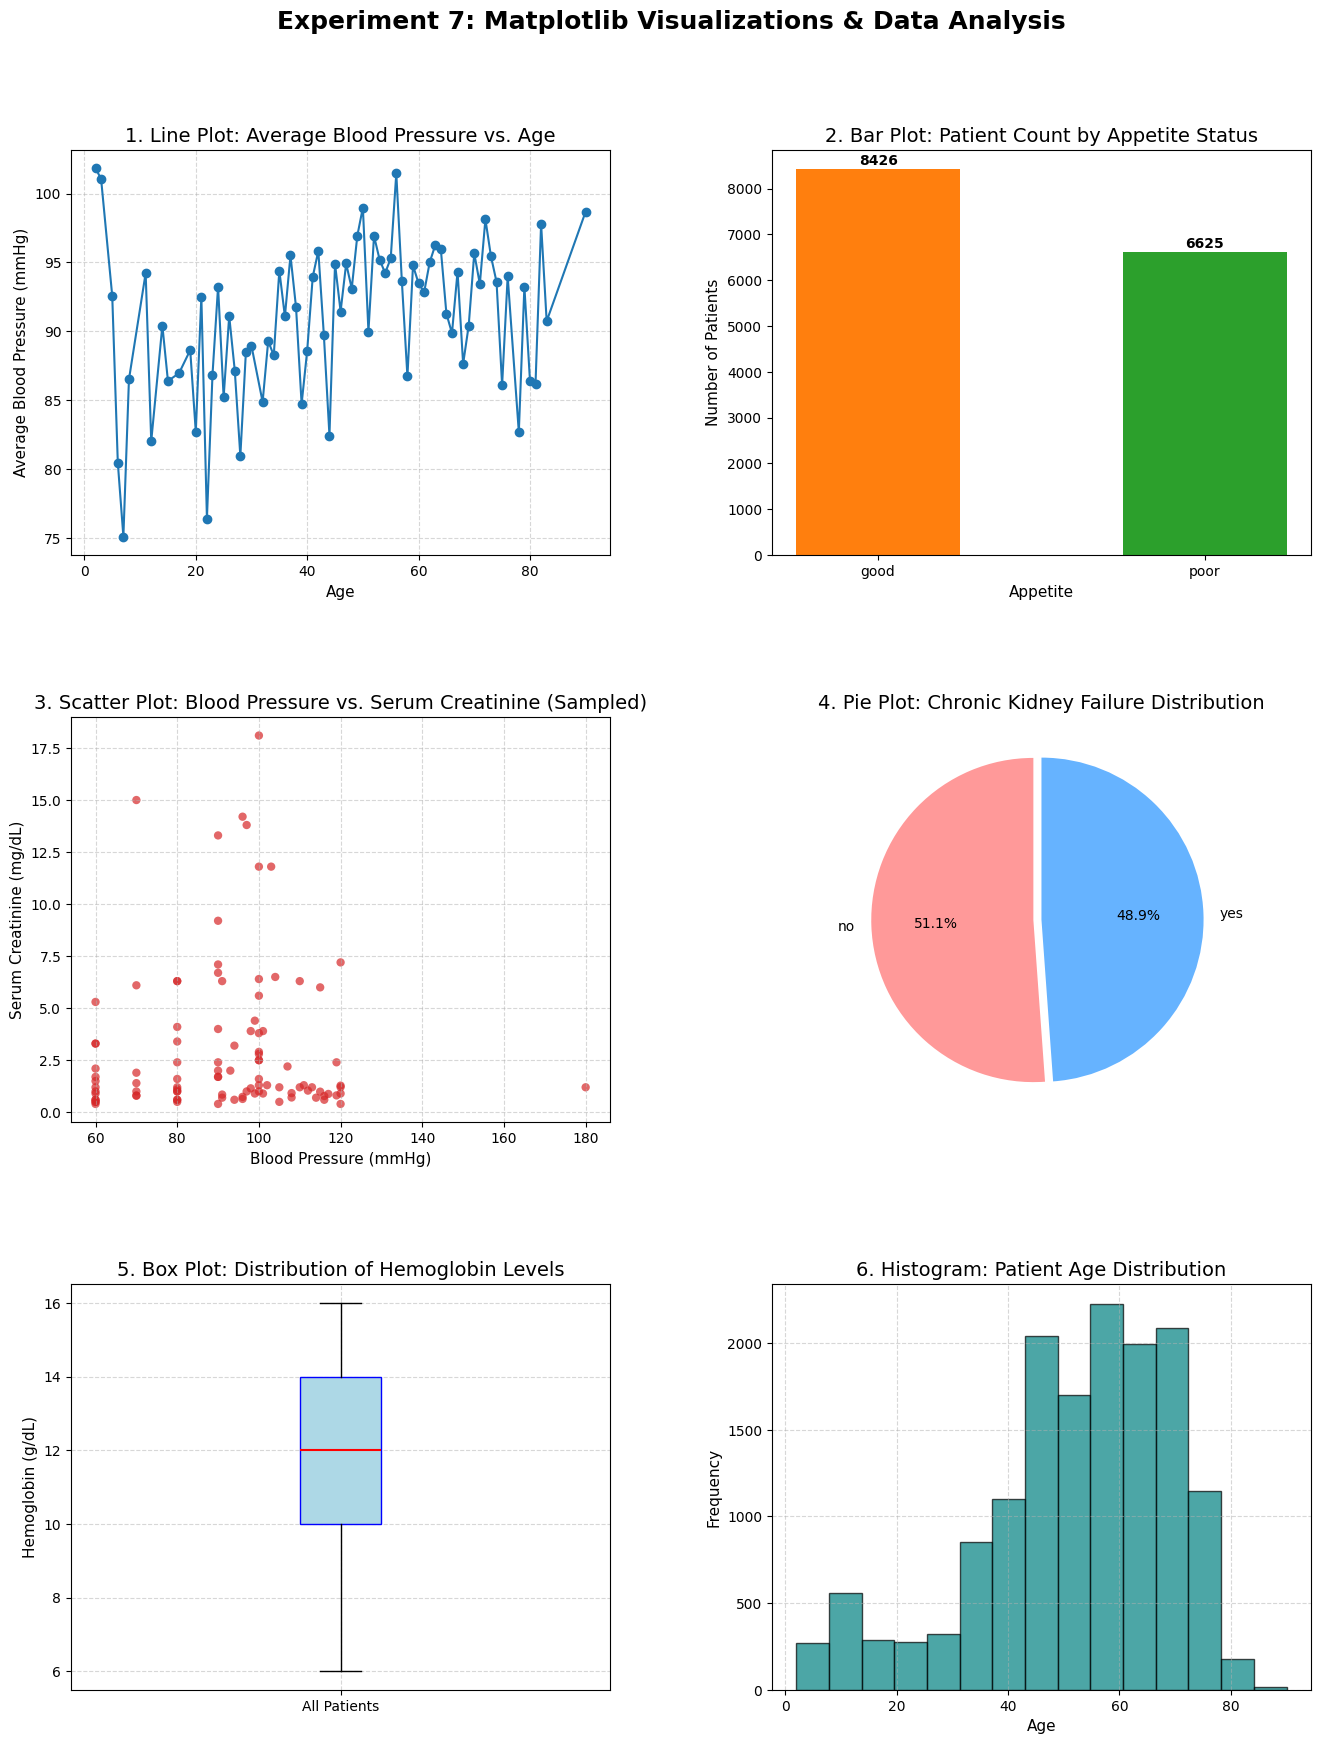

In [7]:
plt.rcParams['figure.figsize'] = (15, 20)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

sample_data = data.sample(n=100, random_state=42) if len(data) > 100 else data
line_data = data.groupby('Age')['Blood Pressure'].mean().reset_index().sort_values('Age')

fig, axes = plt.subplots(3, 2, figsize=(16, 20))
fig.subplots_adjust(hspace=0.4, wspace=0.3)

# 1. Line Plot: Average Blood Pressure by Age
axes[0, 0].plot(line_data['Age'], line_data['Blood Pressure'], color='tab:blue', marker='o', linestyle='-', linewidth=1.5)
axes[0, 0].set_title('1. Line Plot: Average Blood Pressure vs. Age')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Average Blood Pressure (mmHg)')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# 2. Bar Plot: Patient count by Appetite Status
appetite_counts = data['Apetite'].value_counts()
axes[0, 1].bar(appetite_counts.index, appetite_counts.values, color=['tab:orange', 'tab:green'], width=0.5)
axes[0, 1].set_title('2. Bar Plot: Patient Count by Appetite Status')
axes[0, 1].set_xlabel('Appetite')
axes[0, 1].set_ylabel('Number of Patients')
for i, val in enumerate(appetite_counts.values):
    axes[0, 1].text(i, val + (max(appetite_counts.values) * 0.01), str(val), ha='center', fontweight='bold')

# 3. Scatter Plot: Blood Pressure vs. Serum Creatinine
axes[1, 0].scatter(sample_data['Blood Pressure'], sample_data['Serum Creatinine'], color='tab:red', alpha=0.7, edgecolors='none')
axes[1, 0].set_title('3. Scatter Plot: Blood Pressure vs. Serum Creatinine (Sampled)')
axes[1, 0].set_xlabel('Blood Pressure (mmHg)')
axes[1, 0].set_ylabel('Serum Creatinine (mg/dL)')
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# 4. Pie Plot: Chronic Kidney Failure Distribution
ckd_counts = data['Chronic kidney failure'].value_counts()
axes[1, 1].pie(ckd_counts.values, labels=ckd_counts.index, autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], startangle=90, explode=(0.05, 0))
axes[1, 1].set_title('4. Pie Plot: Chronic Kidney Failure Distribution')

# 5. Box Plot: Distribution of Hemoglobin Levels
axes[2, 0].boxplot(data['Hemoglobin'].dropna(), vert=True, patch_artist=True,
                  boxprops=dict(facecolor='lightblue', color='blue'),
                  medianprops=dict(color='red', linewidth=1.5))
axes[2, 0].set_title('5. Box Plot: Distribution of Hemoglobin Levels')
axes[2, 0].set_ylabel('Hemoglobin (g/dL)')
axes[2, 0].set_xticklabels(['All Patients'])
axes[2, 0].grid(True, linestyle='--', alpha=0.5)

# 6. Histogram Plot: Age Distribution of Patients
axes[2, 1].hist(data['Age'].dropna(), bins=15, color='teal', edgecolor='black', alpha=0.7)
axes[2, 1].set_title('6. Histogram: Patient Age Distribution')
axes[2, 1].set_xlabel('Age')
axes[2, 1].set_ylabel('Frequency')
axes[2, 1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Experiment 7: Matplotlib Visualizations & Data Analysis", fontsize=18, y=0.95, fontweight='bold')
plt.show()

### **Interpretations and Results**

1. **Line Plot (Average Blood Pressure vs. Age):**
   - *Interpretation:* Shows how average blood pressure fluctuates across different age brackets. It identifies variations and age milestones where blood pressure tends to climb.

2. **Bar Plot (Patient Count by Appetite Status):**
   - *Interpretation:* Compares categorical distribution directly. We can clearly observe whether more patients fall into the 'poor' or 'good' appetite category.

3. **Scatter Plot (Blood Pressure vs. Serum Creatinine):**
   - *Interpretation:* Illustrates the relationship between blood pressure levels and renal function (Serum Creatinine levels) on an individual level. It highlights clusters and outliers.

4. **Pie Plot (Chronic Kidney Failure Distribution):**
   - *Interpretation:* Visually details the percentage composition of patients diagnosed with vs. without chronic kidney disease.

5. **Box Plot (Distribution of Hemoglobin Levels):**
   - *Interpretation:* Represents the five-number summary (Minimum, Q1, Median, Q3, Maximum) for patient Hemoglobin levels. This visual makes it simple to observe variance, skewness, and outliers in patients' oxygen-carrying capacity.

6. **Histogram (Patient Age Distribution):**
   - *Interpretation:* Demonstrates the continuous frequency distribution of patient ages, indicating which demographic is most prevalent in the sample dataset.

